# Phase 16 — Performance on candidates excluded by the legacy-similarity filter
Owner: Shafin. Run in the existing **enhancer** environment. This is frozen-checkpoint inference, not model training. All inputs, caches and outputs stay in this contribution folder. Earlier notebooks and results are read only.

**Question:** Do the already-trained models perform differently on retained and removed assay candidates from the original chromosome-held-out test partition?

The intended comparison includes DNABERT-2, MPRA-LegNet and MPRAnn. Only the CNN checkpoints are currently supplied; DNABERT-2 is explicitly pending, never reconstructed from a pretrained model or substituted with a newly trained model. The CNN analysis is executable independently. Both favourable and unfavourable results are retained.

Primary evaluation: original five test chromosomes, with exact/RC matches to either cell's training/validation records excluded and genomic separation checked. Secondary sensitivity: additionally exclude any canonical 31-mer match to the pooled training/validation sequences. These are screens for particular similarities, not proof of complete independence. Report the sensitivity exclusions rather than silently redefining the removed population.

Report correlations and absolute activity errors separately. Differences between populations are descriptive selection/transport findings, not the causal effect of retraining with or without filtering. The population distributions were examined in Phase 14; this is a retrospective extension. Bootstrap intervals condition on fixed models and partitions. No model/threshold selection from these outcomes.

In [1]:
from pathlib import Path
import os,sys,io,json,zipfile,hashlib,math,gc,time,datetime
import numpy as np,pandas as pd
from scipy.stats import spearmanr
import torch
from torch import nn
import torch.nn.functional as F
ROOT=Path(r"D:\Aditta Thesis\For Shafin\Shafin's Contribution").resolve()
assert Path(sys.executable).resolve()==Path(r'C:\Users\User\.conda\envs\enhancer\python.exe').resolve()
OUT=ROOT/'phase16_outputs';OUT.mkdir(exist_ok=True)
CACHE=OUT/'prediction_cache';CACHE.mkdir(exist_ok=True)
os.environ['MPLCONFIGDIR']=str(OUT/'matplotlib_cache')
P12=ROOT/'phase12_outputs/enhancer_phase12_work'
def fsha(p):
 with Path(p).open('rb') as f:return hashlib.file_digest(f,'sha256').hexdigest()
def sha(b):return hashlib.sha256(b).hexdigest()
def dump(name,obj):
 p=OUT/name;raw=json.dumps(obj,indent=2,sort_keys=True,allow_nan=False)+'\n'
 if p.exists() and name=='frozen_protocol.json':assert p.read_text(encoding='utf8')==raw,'Protocol changed: use a new analysis version.'
 else:p.write_text(raw,encoding='utf8')
def table(name,d):d.to_csv(OUT/name,index=False,float_format='%.12g',compression={'method':'gzip','mtime':0} if name.endswith('.gz') else None)
def member(name):
 found=[]
 for folder in ('phase12_inputs','reference_inputs'):
  for p in (ROOT/folder).glob('*.zip'):
   with zipfile.ZipFile(p) as z:
    for n in z.namelist():
     if n.split('/')[-1]==name:found.append(z.read(n))
 assert found and len({sha(b) for b in found})==1,name
 return found[0]
prov=json.loads((P12/'results/phase12_provenance.json').read_text())
assert prov['smoke_test'] is False
raw=member('phase9_full_activity_all_cells.csv')
assert sha(raw)==prov['config']['input_sha256']['phase9_full_activity_all_cells.csv']
DATA=pd.read_csv(io.BytesIO(raw));POP=pd.read_csv(ROOT/'phase14_outputs/reconstructed_filtering_population.csv.gz')
assert len(DATA)==76833 and len(POP)==149632 and POP.record_id.is_unique
ret=POP[POP.population.eq('retained')].set_index('record_id').sort_index()
ref=DATA.set_index('record_id').sort_index()
assert ret.index.equals(ref.index) and ret.sequence.equals(ref.sequence)
assert np.max(abs(ret.mean_log2_activity-ref.mean_log2_activity))<1e-9
CONFIG=prov['config'];SEEDS=CONFIG['seeds'];MODELS=['legnet','mprann'];CELLS=['HepG2','K562']
protected={p.relative_to(ROOT).as_posix():fsha(p) for p in [ROOT/'[12] Enhancer_Kaggle_Phase12_Strong_Baselines.ipynb',ROOT/'phase14_outputs/reconstructed_filtering_population.csv.gz',P12/'results/phase12_provenance.json']}
for name,spec in prov['checkpoints'].items():
 p=P12/'checkpoints'/name;assert fsha(p)==spec['sha256'];protected[p.relative_to(ROOT).as_posix()]=spec['sha256']
for name,h in prov['result_sha256'].items():assert fsha(P12/'results'/name)==h
audit=json.loads(member('phase9a_audit_and_provenance.json'))
CHROMS=audit['phase7_chromosome_assignment'];assert set(CHROMS)=={'train','validation','test'}
assert set(DATA.loc[DATA.split_9b.eq('test'),'chrom'])==set(CHROMS['test'])
SPEC={'name':'phase16_filtered_out_frozen_cnn_v1','parent_phase12':prov['protocol_sha256'],
 'population_sha256':protected['phase14_outputs/reconstructed_filtering_population.csv.gz'],
 'chromosomes':CHROMS,'models':MODELS,'seeds':SEEDS,'dnabert2_status':'pending original fine-tuned checkpoints; absent from supplied inputs',
 'primary':'test chromosomes; exclude pooled train/validation exact or RC identity and genomic intersection',
 'sensitivity':'add canonical 31-mer exclusion against pooled train/validation; report attrition',
 'strand_policy':'average forward and reverse-complement; same original target scaling',
 'bootstrap_repeats':1000,'bootstrap_seed':2026101616,'bootstrap_groups':'1 kb genomic regions joined for exact/RC sequence identity within each cell',
 'intervals':'fixed-model conditional percentile 95%; exploratory, no multiplicity adjustment',
 'subgroups':'Phase 14 fixed GC, homopolymer and training-derived activity bins; min n=100',
 'calibration_split_for_possible_followup':'region hash phase17-v1, first 30% calibration; remaining audit; no fitting in Phase 16',
 'inference_batch':1024,'amp':'float16 on CUDA; no training','retained_reproduction_max_error':0.005}
dump('frozen_protocol.json',SPEC);LOCK=sha(json.dumps(SPEC,sort_keys=True,separators=(',',':')).encode())
dump('protected_input_hashes.json',protected)
print('Frozen protocol',LOCK,'; test chromosomes',CHROMS['test'])

Frozen protocol 50af48144100d0bbad465fd0838efeacc257aa56185c2d6e19e3fd43ed9cd6b4 ; test chromosomes ['chr1', 'chr12', 'chr4', 'chr7', 'chr9']


## 1. Define evaluation records and audit similarity before scoring
The primary removed group contains only candidates on the previously frozen test chromosomes. Training and validation chromosomes remain excluded. Exact/RC identity and 31-mer sharing are checked against both cell models' training/validation inputs; this pooled screen is conservative. Removed candidates on training or validation chromosomes are not treated as test data.

The region-hash calibration/audit assignment is fixed here before model outcomes are computed, for an optional later reliability study. Genomic dependence and earlier inspection of the retained benchmark still limit formal coverage claims.

In [2]:
COMP=str.maketrans('ACGT','TGCA')
def rc(s):return s.translate(COMP)[::-1]
def canonical(s):return min(s,rc(s))
reference=DATA[DATA.split_9b.isin(['train','validation'])].copy()
reference_keys=set(reference.sequence.map(canonical))
TEST=POP[POP.chrom.isin(CHROMS['test'])].copy().reset_index(drop=True)
TEST['canonical_sequence']=TEST.sequence.map(canonical)
TEST['exact_rc_train_validation']=TEST.canonical_sequence.isin(reference_keys)
assert set(TEST.chrom).isdisjoint(reference.chrom)
TEST['genomic_overlap_train_validation']=False
TEST['eligible_primary']=~TEST.exact_rc_train_validation
K=31;MASK=np.uint64((1<<(2*K))-1);LUT=np.zeros(256,dtype=np.uint64)
for j,b in enumerate(b'ACGT'):LUT[b]=j
def words(sequences):
 codes=LUT[np.stack([np.frombuffer(s.encode(),dtype=np.uint8) for s in sequences])]
 f=np.zeros(len(codes),dtype=np.uint64);r=f.copy();out=[]
 for i in range(200):
  f=((f<<np.uint64(2))|codes[:,i])&MASK
  r=(r>>np.uint64(2))|((np.uint64(3)-codes[:,i])<<np.uint64(60))
  if i>=30:out.append(np.minimum(f,r))
 return np.stack(out,axis=1)
reference_words=np.unique(words(reference.sequence.drop_duplicates().tolist()).ravel())
hits=[]
for start in range(0,len(TEST),1000):
 w=words(TEST.sequence.iloc[start:start+1000].tolist());ix=np.searchsorted(reference_words,w)
 valid=ix<len(reference_words);match=np.zeros(w.shape,bool);match[valid]=reference_words[ix[valid]]==w[valid]
 hits.extend(match.any(axis=1).tolist())
TEST['shared_31mer_train_validation']=hits
TEST['eligible_31mer_sensitivity']=TEST.eligible_primary&~TEST.shared_31mer_train_validation
del reference_words;gc.collect()
# Build genomic groups, then union groups connected by an identical/RC DNA sequence.
for cell,g in TEST.groupby('cell_line'):
 parent={};row_region={};counter=0
 for chrom,part in g.groupby('chrom'):
  edge=-1;current=None
  for row in part.sort_values(['start','end','record_id']).itertuples():
   if current is None or row.start>edge+1000:
    current=f'{cell}:{chrom}:{counter}';parent[current]=current;counter+=1
   edge=max(edge,row.end);row_region[row.Index]=current
 def find(x):
  while parent[x]!=x:parent[x]=parent[parent[x]];x=parent[x]
  return x
 seen={}
 for row in g.itertuples():
  reg=row_region[row.Index];key=row.canonical_sequence
  if key in seen:
   a,b=find(reg),find(seen[key]);parent[max(a,b)]=min(a,b)
  else:seen[key]=reg
 for ix,reg in row_region.items():TEST.loc[ix,'resampling_group']=find(reg)
TEST['followup_partition']=TEST.resampling_group.map(lambda s:'calibration' if int(sha(('phase17-v1:'+s).encode())[:8],16)%100<30 else 'audit')
assert TEST.groupby(['cell_line','canonical_sequence']).resampling_group.nunique().max()==1
TEST['gc_fraction']=TEST.sequence.map(lambda s:(s.count('G')+s.count('C'))/200)
import itertools
TEST['max_homopolymer']=TEST.sequence.map(lambda s:max(len(list(g)) for _,g in itertools.groupby(s)))
TEST['cpg_density']=TEST.sequence.map(lambda s:s.count('CG')/199)
table('evaluation_cohort.csv.gz',TEST.drop(columns='canonical_sequence'))
attrition=TEST.groupby(['cell_line','population'],as_index=False).agg(test_chromosome_candidates=('record_id','size'),
 exact_rc_exclusions=('exact_rc_train_validation','sum'),primary_eligible=('eligible_primary','sum'),
 shared_31mer=('shared_31mer_train_validation','sum'),clean_31mer_eligible=('eligible_31mer_sensitivity','sum'))
table('evaluation_attrition.csv',attrition)
print(attrition.to_string(index=False))
print('Reference sequences',len(reference),'and chromosome-separated evaluation records',len(TEST))

cell_line population  test_chromosome_candidates  exact_rc_exclusions  primary_eligible  shared_31mer  clean_31mer_eligible
    HepG2    removed                        8436                    0              8436           199                  8237
    HepG2   retained                        9048                    0              9048           230                  8818
     K562    removed                       12702                    0             12702           393                 12309
     K562   retained                       13145                    0             13145           380                 12765
Reference sequences 54640 and chromosome-separated evaluation records 43331


## 2. Frozen architectures and inference
The architecture definitions below are copied from the authenticated Phase 12 notebook, with provenance in the frozen protocol. No optimizer or training code is executed. Every checkpoint is authenticated and loaded strictly. We first reproduce predictions on the original retained test set; a substantial discrepancy stops analysis. New inference is cached with sequence identities and checkpoint hashes.

The acceptance tolerance allows small floating-point differences across GPU kernels; observed maximum, mean and score differences are reported explicitly, not hidden by the threshold. Cached results are reusable only with exactly matching inputs and weights.

In [3]:
DEVICE=torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
torch.backends.cudnn.benchmark=False
torch.backends.cudnn.deterministic=True
torch.use_deterministic_algorithms(True,warn_only=True)
# MIT License
# Copyright 2024 Dmitry Penzar
# Permission is hereby granted, free of charge, to any person obtaining a copy of this software and associated documentation files (the “Software”), to deal in the Software without restriction, including without limitation the rights to use, copy, modify, merge, publish, distribute, sublicense, and/or sell copies of the Software, and to permit persons to whom the Software is furnished to do so, subject to the following conditions:
# The above copyright notice and this permission notice shall be included in all copies or substantial portions of the Software.
# THE SOFTWARE IS PROVIDED “AS IS”, WITHOUT WARRANTY OF ANY KIND, EXPRESS OR IMPLIED, INCLUDING BUT NOT LIMITED TO THE WARRANTIES OF MERCHANTABILITY, FITNESS FOR A PARTICULAR PURPOSE AND NONINFRINGEMENT. IN NO EVENT SHALL THE AUTHORS OR COPYRIGHT HOLDERS BE LIABLE FOR ANY CLAIM, DAMAGES OR OTHER LIABILITY, WHETHER IN AN ACTION OF CONTRACT, TORT OR OTHERWISE, ARISING FROM, OUT OF OR IN CONNECTION WITH THE SOFTWARE OR THE USE OR OTHER DEALINGS IN THE SOFTWARE.
# 
# 
# MIT License
# 
# Copyright (c) 2022, Max Schubach, Berlin Institute of Health (BIH)
# 
# Permission is hereby granted, free of charge, to any person obtaining a copy
# of this software and associated documentation files (the "Software"), to deal
# in the Software without restriction, including without limitation the rights
# to use, copy, modify, merge, publish, distribute, sublicense, and/or sell
# copies of the Software, and to permit persons to whom the Software is
# furnished to do so, subject to the following conditions:
# 
# The above copyright notice and this permission notice shall be included in all
# copies or substantial portions of the Software.
# 
# THE SOFTWARE IS PROVIDED "AS IS", WITHOUT WARRANTY OF ANY KIND, EXPRESS OR
# IMPLIED, INCLUDING BUT NOT LIMITED TO THE WARRANTIES OF MERCHANTABILITY,
# FITNESS FOR A PARTICULAR PURPOSE AND NONINFRINGEMENT. IN NO EVENT SHALL THE
# AUTHORS OR COPYRIGHT HOLDERS BE LIABLE FOR ANY CLAIM, DAMAGES OR OTHER
# LIABILITY, WHETHER IN AN ACTION OF CONTRACT, TORT OR OTHERWISE, ARISING FROM,
# OUT OF OR IN CONNECTION WITH THE SOFTWARE OR THE USE OR OTHER DEALINGS IN THE
# SOFTWARE.

# ---- MPRA-LegNet. Copied from autosome-ru/human_legnet model.py (commit a20dbc7).
# MIT License, Copyright 2024 Dmitry Penzar. Permission is hereby granted, free of charge, to any person
# obtaining a copy of this software ... The above copyright notice and this permission notice shall be
# included in all copies or substantial portions of the Software. (Full text: repository LICENSE.)
def initialize_weights(m):
    if isinstance(m, nn.Conv1d):
        n = m.kernel_size[0] * m.out_channels
        m.weight.data.normal_(0, math.sqrt(2 / n))
        if m.bias is not None: nn.init.constant_(m.bias.data, 0)
    elif isinstance(m, nn.BatchNorm1d):
        nn.init.constant_(m.weight.data, 1); nn.init.constant_(m.bias.data, 0)
    elif isinstance(m, nn.Linear):
        m.weight.data.normal_(0, 0.001)
        if m.bias is not None: nn.init.constant_(m.bias.data, 0)
class SELayer(nn.Module):
    def __init__(self, inp, reduction=4):
        super().__init__()
        self.fc = nn.Sequential(nn.Linear(inp, int(inp // reduction)), nn.SiLU(), nn.Linear(int(inp // reduction), inp), nn.Sigmoid())
    def forward(self, x):
        b, c, _, = x.size(); y = x.view(b, c, -1).mean(dim=2); y = self.fc(y).view(b, c, 1); return x * y
class EffBlock(nn.Module):
    def __init__(self, in_ch, ks, resize_factor, activation, out_ch=None, se_reduction=None):
        super().__init__()
        self.in_ch = in_ch; self.out_ch = self.in_ch if out_ch is None else out_ch
        self.resize_factor = resize_factor; self.se_reduction = resize_factor if se_reduction is None else se_reduction
        self.ks = ks; self.inner_dim = self.in_ch * self.resize_factor
        self.block = nn.Sequential(
            nn.Conv1d(self.in_ch, self.inner_dim, kernel_size=1, padding='same', bias=False), nn.BatchNorm1d(self.inner_dim), activation(),
            nn.Conv1d(self.inner_dim, self.inner_dim, kernel_size=ks, groups=self.inner_dim, padding='same', bias=False),
            nn.BatchNorm1d(self.inner_dim), activation(), SELayer(self.inner_dim, reduction=self.se_reduction),
            nn.Conv1d(self.inner_dim, self.in_ch, kernel_size=1, padding='same', bias=False), nn.BatchNorm1d(self.in_ch), activation())
    def forward(self, x): return self.block(x)
class LocalBlock(nn.Module):
    def __init__(self, in_ch, ks, activation, out_ch=None):
        super().__init__()
        self.in_ch = in_ch; self.out_ch = self.in_ch if out_ch is None else out_ch; self.ks = ks
        self.block = nn.Sequential(nn.Conv1d(self.in_ch, self.out_ch, kernel_size=self.ks, padding='same', bias=False),
                                   nn.BatchNorm1d(self.out_ch), activation())
    def forward(self, x): return self.block(x)
class ResidualConcat(nn.Module):
    def __init__(self, fn): super().__init__(); self.fn = fn
    def forward(self, x, **kwargs): return torch.concat([self.fn(x, **kwargs), x], dim=1)
class MapperBlock(nn.Module):
    def __init__(self, in_features, out_features, activation=nn.SiLU):
        super().__init__()
        self.block = nn.Sequential(nn.BatchNorm1d(in_features), nn.Conv1d(in_features, out_features, kernel_size=1))
    def forward(self, x): return self.block(x)
class LegNet(nn.Module):
    def __init__(self, in_ch, stem_ch, stem_ks, ef_ks, ef_block_sizes, pool_sizes, resize_factor, activation=nn.SiLU):
        super().__init__()
        assert len(pool_sizes) == len(ef_block_sizes)
        self.in_ch = in_ch
        self.stem = LocalBlock(in_ch=in_ch, out_ch=stem_ch, ks=stem_ks, activation=activation)
        blocks = []; in_ch = stem_ch; out_ch = stem_ch
        for pool_sz, out_ch in zip(pool_sizes, ef_block_sizes):
            blocks.append(nn.Sequential(
                ResidualConcat(EffBlock(in_ch=in_ch, out_ch=in_ch, ks=ef_ks, resize_factor=resize_factor, activation=activation)),
                LocalBlock(in_ch=in_ch * 2, out_ch=out_ch, ks=ef_ks, activation=activation),
                nn.MaxPool1d(pool_sz) if pool_sz != 1 else nn.Identity()))
            in_ch = out_ch
        self.main = nn.Sequential(*blocks)
        self.mapper = MapperBlock(in_features=out_ch, out_features=out_ch * 2)
        self.head = nn.Sequential(nn.Linear(out_ch * 2, out_ch * 2), nn.BatchNorm1d(out_ch * 2), activation(), nn.Linear(out_ch * 2, 1))
    def forward(self, x):
        x = self.stem(x); x = self.main(x); x = self.mapper(x)
        x = F.adaptive_avg_pool1d(x, 1).squeeze(-1); return self.head(x).squeeze(-1)
# ---- end of copied LegNet code.

class MPRAnn(nn.Module):
    """PyTorch port of `standard()` in visze/sequence_cnn_models lib/model.py (MIT, Max Schubach / BIH).
    Keras Conv1D uses 'valid' padding; activation precedes BatchNormalization; softmax is over channels;
    Keras BN defaults (momentum 0.99, eps 1e-3) and glorot_uniform/zero initialisation are reproduced."""
    def __init__(self, length=200):
        super().__init__()
        bn = lambda c: nn.BatchNorm1d(c, eps=1e-3, momentum=0.01)
        self.c1, self.b1 = nn.Conv1d(4, 250, 7), bn(250)
        self.c2, self.b2 = nn.Conv1d(250, 250, 8), bn(250)
        self.c3, self.b3 = nn.Conv1d(250, 250, 3), bn(250)
        self.c4, self.b4 = nn.Conv1d(250, 100, 2), bn(100)
        self.drop1, self.drop2, self.drop3 = nn.Dropout(0.1), nn.Dropout(0.1), nn.Dropout(0.3)
        L = ((length - 6 - 7) // 2) - 2 - 1
        self.d1, self.d2, self.out = nn.Linear(100 * L, 300), nn.Linear(300, 200), nn.Linear(200, 1)
        for m in self.modules():
            if isinstance(m, (nn.Conv1d, nn.Linear)): nn.init.xavier_uniform_(m.weight); nn.init.zeros_(m.bias)
    def forward(self, x):
        x = self.b1(F.relu(self.c1(x)))
        x = self.b2(torch.softmax(self.c2(x), dim=1)); x = self.drop1(F.max_pool1d(x, 2))
        x = self.b3(torch.softmax(self.c3(x), dim=1))
        x = self.b4(torch.softmax(self.c4(x), dim=1)); x = self.drop2(x)
        x = x.transpose(1, 2).flatten(1)   # Keras Flatten order (length, channels)
        x = self.drop3(torch.sigmoid(self.d1(x))); x = torch.sigmoid(self.d2(x))
        return self.out(x).squeeze(-1)

def build(model):
    if model == 'legnet':
        c = CONFIG['legnet']
        net = LegNet(in_ch=c['in_ch'], stem_ch=c['stem_ch'], stem_ks=c['stem_ks'], ef_ks=c['ef_ks'],
                     ef_block_sizes=c['ef_block_sizes'], pool_sizes=c['pool_sizes'], resize_factor=c['resize_factor'])
        net.apply(initialize_weights); return net
    return MPRAnn()

In [4]:
EYE=np.eye(4,dtype=np.float32)
def onehot(seqs):
 c=np.stack([LUT[np.frombuffer(s.encode(),dtype=np.uint8)].astype(np.int64) for s in seqs])
 return torch.from_numpy(EYE[c].transpose(0,2,1).copy())
def infer(net,seqs,mean,scale):
 net.eval();out=[]
 with torch.inference_mode():
  for i in range(0,len(seqs),SPEC['inference_batch']):
   part=seqs[i:i+SPEC['inference_batch']]
   x=onehot(part).to(DEVICE);xr=onehot([rc(s) for s in part]).to(DEVICE)
   with torch.autocast(DEVICE.type,dtype=torch.float16,enabled=DEVICE.type=='cuda'):
    a=net(x).float();b=net(xr).float()
   out.append(((a+b)/2*scale+mean).cpu().numpy())
 return np.concatenate(out).astype(float)
rows=[];reproductions=[];weight_rows=[]
for cell in CELLS:
 original=DATA[DATA.cell_line.eq(cell)&DATA.split_9b.eq('test')].reset_index(drop=True)
 removed=TEST[TEST.cell_line.eq(cell)&TEST.population.eq('removed')].reset_index(drop=True)
 for model in MODELS:
  for seed in SEEDS:
   job=f'9b_{cell}_{model}_seed_{seed}';path=P12/'checkpoints'/f'{job}_best.pt';ckhash=fsha(path)
   ck=torch.load(path,map_location='cpu',weights_only=True)
   assert ck['lock']==prov['protocol_sha256'] and ck['job']==job
   tr=DATA[DATA.cell_line.eq(cell)&DATA.split_9b.eq('train')].mean_log2_activity.to_numpy(np.float32)
   assert abs(float(tr.mean())-ck['target_mean'])<1e-7 and abs(float(tr.std())-ck['target_scale'])<1e-7
   net=build(model).to(DEVICE);net.load_state_dict(ck['state_dict'],strict=True)
   for population,part in [('retained',original),('removed',removed)]:
    cache=CACHE/f'{job}_{population}.csv';meta=cache.with_suffix('.json')
    identity=sha('\n'.join(part.record_id+':'+part.sequence_sha256).encode())
    if cache.exists() and meta.exists():
     m=json.loads(meta.read_text());assert m['lock']==LOCK and m['checkpoint_sha256']==ckhash and m['input_sha256']==identity
     assert fsha(cache)==m['prediction_sha256'];scores=pd.read_csv(cache,float_precision='round_trip')
     assert scores.record_id.tolist()==part.record_id.tolist()
     p=scores.prediction.to_numpy().astype(np.float32).astype(float)
     assert np.max(abs(p-scores.prediction.to_numpy()))<1e-13, 'Restore original float32 inference values without changing predictions.'
    else:
     p=infer(net,part.sequence.tolist(),ck['target_mean'],ck['target_scale'])
     pd.DataFrame({'record_id':part.record_id,'prediction':p}).to_csv(cache,index=False,float_format='%.17g')
     meta.write_text(json.dumps({'lock':LOCK,'checkpoint_sha256':ckhash,'input_sha256':identity,'prediction_sha256':fsha(cache),'device':str(DEVICE)},indent=2),encoding='utf8')
    assert np.isfinite(p).all()
    if population=='retained':
     oldp=pd.read_csv(P12/'predictions'/f'{job}_test.csv').set_index('record_id').loc[part.record_id,'prediction'].to_numpy()
     error=abs(p-oldp);assert error.max()<SPEC['retained_reproduction_max_error'],(job,error.max())
     reproductions.append(dict(job=job,n=len(p),max_abs_error=float(error.max()),mean_abs_error=float(error.mean()),
       pearson_difference=float(np.corrcoef(part.mean_log2_activity,p)[0,1]-np.corrcoef(part.mean_log2_activity,oldp)[0,1])))
    rows.append(pd.DataFrame({'record_id':part.record_id,'cell_line':cell,'population':population,'model':model,'seed':seed,'prediction':p}))
   weight_rows.append(dict(job=job,checkpoint_sha256=ckhash,epoch=ck['epoch'],target_mean=ck['target_mean'],target_scale=ck['target_scale']))
   del net,ck;gc.collect();torch.cuda.empty_cache()
   print('Completed frozen inference:',job,flush=True)
PRED=pd.concat(rows,ignore_index=True)
table('seed_predictions.csv.gz',PRED)
ensemble=PRED.groupby(['record_id','cell_line','population','model'],as_index=False).agg(prediction=('prediction','mean'),seed_sd=('prediction','std'),seeds=('seed','nunique'))
assert ensemble.seeds.eq(3).all()
SCORED=ensemble.merge(TEST.drop(columns=['canonical_sequence','cell_line','population']),on='record_id',validate='many_to_one')
assert len(SCORED)==len(TEST)*len(MODELS)
table('ensemble_predictions_and_metadata.csv.gz',SCORED)
table('retained_prediction_reproduction.csv',pd.DataFrame(reproductions));table('loaded_checkpoint_metadata.csv',pd.DataFrame(weight_rows))
print('Largest retained prediction discrepancy',max(x['max_abs_error'] for x in reproductions))

Completed frozen inference: 9b_HepG2_legnet_seed_20260930


Completed frozen inference: 9b_HepG2_legnet_seed_20260931


Completed frozen inference: 9b_HepG2_legnet_seed_20260932


Completed frozen inference:

 9b_HepG2_mprann_seed_20260930


...

 9b_K562_legnet_seed_20260932


Completed frozen inference: 9b_K562_mprann_seed_20260930


Completed frozen inference: 9b_K562_mprann_seed_20260931


Completed frozen inference: 9b_K562_mprann_seed_20260932


Largest retained prediction discrepancy 5.000000413701855e-12


## 3. Compare performance and conditional uncertainty
Complete genomic/identity groups are resampled together. Each bootstrap draw is shared across both models and both populations within a cell. This retains paired model comparisons and dependence between nearby retained/removed candidates. Pearson, RMSE and MAE intervals are computed from exact resampled moments; Spearman is reported as a point estimate only. Intervals are exploratory and conditional, with no multiplicity correction.

The 31-mer-clean sensitivity is a different, more selected population; a changed result there cannot be attributed solely to leakage removal. A filter-performance difference is not a causal estimate because activity and DNA composition also differ.

In [5]:
def measure(g):
 y=g.mean_log2_activity.to_numpy(float);p=g.prediction.to_numpy(float);e=p-y
 return dict(n=len(g),groups=g.resampling_group.nunique(),pearson=float(np.corrcoef(y,p)[0,1]),
  spearman=float(spearmanr(y,p).statistic),rmse=float(np.sqrt(np.mean(e*e))),mae=float(np.mean(abs(e))),
  r2=float(1-np.sum(e*e)/np.sum((y-y.mean())**2)),signed_error=float(np.mean(e)),target_sd=float(np.std(y)))
metric_rows=[];ci_rows=[];gap_rows=[]
for analysis,flag in [('primary','eligible_primary'),('31mer_sensitivity','eligible_31mer_sensitivity')]:
 for cell,allg in SCORED[SCORED[flag]].groupby('cell_line'):
  keys=sorted(allg.resampling_group.unique());rng=np.random.default_rng(SPEC['bootstrap_seed'])
  stats={};point={};boot={}
  for (population,model),g in allg.groupby(['population','model']):
   point[population,model]=measure(g)
   metric_rows.append(dict(analysis=analysis,cell_line=cell,population=population,model=model,**point[population,model]))
   y=g.mean_log2_activity.to_numpy(float);p=g.prediction.to_numpy(float)
   v=pd.DataFrame({'group':g.resampling_group,'n':1.,'y':y,'p':p,'yy':y*y,'pp':p*p,'yp':y*p,'ae':abs(p-y),'se':(p-y)**2})
   stats[population,model]=v.groupby('group').sum().reindex(keys,fill_value=0).to_numpy()
   boot[population,model]=[]
  for begin in range(0,SPEC['bootstrap_repeats'],50):
   b=min(50,SPEC['bootstrap_repeats']-begin)
   weights=np.stack([np.bincount(rng.integers(0,len(keys),len(keys)),minlength=len(keys)) for _ in range(b)])
   for key,mom in stats.items():
    v=weights@mom;n,y,p,yy,pp,yp,ae,se=v.T
    pearson=(yp-y*p/n)/np.sqrt(np.maximum((yy-y*y/n)*(pp-p*p/n),0))
    boot[key].append(np.column_stack([pearson,np.sqrt(se/n),ae/n]))
  boot={k:np.concatenate(v) for k,v in boot.items()}
  for key,b in boot.items():
   for j,metric in enumerate(['pearson','rmse','mae']):
    lo,hi=np.quantile(b[:,j],[.025,.975]);ci_rows.append(dict(analysis=analysis,cell_line=cell,population=key[0],model=key[1],metric=metric,estimate=point[key][metric],lo=lo,hi=hi))
  contrasts=[]
  for model in MODELS:contrasts.append((('removed',model),('retained',model),'removed_minus_retained',model))
  for pop in ['retained','removed']:contrasts.append(((pop,'legnet'),(pop,'mprann'),'legnet_minus_mprann',pop))
  for a,b,contrast,label in contrasts:
   for j,metric in enumerate(['pearson','rmse','mae']):
    diff=boot[a][:,j]-boot[b][:,j];lo,hi=np.quantile(diff,[.025,.975])
    gap_rows.append(dict(analysis=analysis,cell_line=cell,contrast=contrast,label=label,metric=metric,
      estimate=point[a][metric]-point[b][metric],lo=lo,hi=hi))
METRICS=pd.DataFrame(metric_rows);GAPS=pd.DataFrame(gap_rows)
table('retained_removed_metrics.csv',METRICS);table('conditional_metric_intervals.csv',pd.DataFrame(ci_rows));table('conditional_contrasts.csv',GAPS)
print(METRICS.round(5).to_string(index=False));print(GAPS[GAPS.analysis.eq('primary')&GAPS.contrast.eq('removed_minus_retained')].round(5).to_string(index=False))

         analysis cell_line population  model     n  groups  pearson  spearman    rmse     mae      r2  signed_error  target_sd
          primary     HepG2    removed legnet  8436    7954  0.65248   0.65691 0.54874 0.40008 0.41005      -0.08845    0.71443
          primary     HepG2    removed mprann  8436    7954  0.65368   0.65962 0.54578 0.39931 0.41639      -0.06913    0.71443
          primary     HepG2   retained legnet  9048    8479  0.66245   0.66550 0.53796 0.39294 0.42584      -0.08089    0.70996
          primary     HepG2   retained mprann  9048    8479  0.65566   0.65950 0.54139 0.39591 0.41850      -0.06791    0.70996
          primary      K562    removed legnet 12702   11061  0.72672   0.65206 0.31374 0.23876 0.52023      -0.00999    0.45295
          primary      K562    removed mprann 12702   11061  0.70441   0.62619 0.32177 0.24439 0.49536      -0.00073    0.45295
          primary      K562   retained legnet 13145   11483  0.70800   0.63889 0.30543 0.23201 0.49453  

## 4. Predefined subgroups and publication figures
Use Phase 14 thresholds without tuning. Activity bands require the measured target and are explanatory diagnostics, not a deployment rule. Correlation in a narrow activity band is affected by restricted target range. Report n and absolute errors alongside it. Groups below n=100 are suppressed.

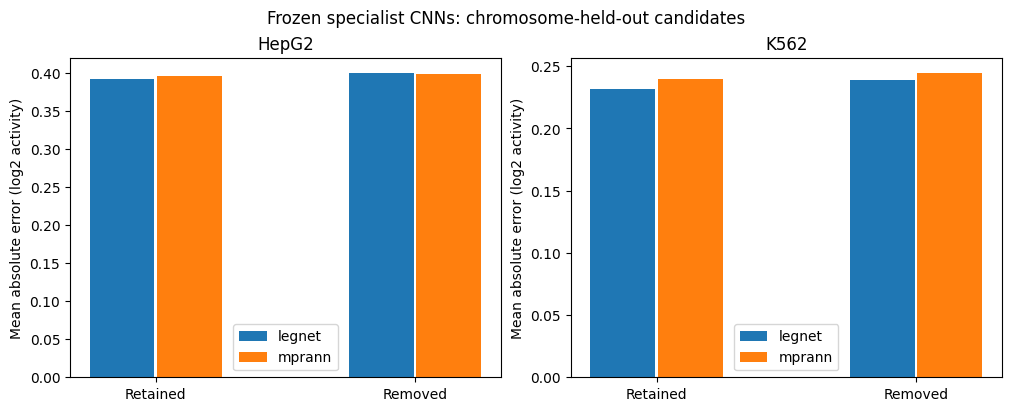

{
  "status": "completed_for_CNNs_DNABERT2_pending",
  "protocol_sha256": "50af48144100d0bbad465fd0838efeacc257aa56185c2d6e19e3fd43ed9cd6b4",
  "training_launched": false,
  "environment": "C:\\Users\\User\\.conda\\envs\\enhancer\\python.exe",
  "device": "cuda:0",
  "test_chromosomes": [
    "chr1",
    "chr12",
    "chr4",
    "chr7",
    "chr9"
  ],
  "original_test_candidates": 43331,
  "removed_test_candidates": 21138,
  "checkpoints_loaded": 12,
  "retained_reproduction_max_error": 5.000000413701855e-12,
  "dnabert2": "Original fine-tuned weights unavailable locally; not replaced or retrained",
  "uncertainty": "1000 paired genomic/identity-group bootstrap draws; fixed models, retrospective comparison, unadjusted intervals",
  "causal_limit": "Different populations, not the effect of training without filtering",
  "protected_inputs_unchanged": true
}


In [6]:
thresholds=pd.read_csv(ROOT/'phase14_outputs/training_only_subgroup_thresholds.csv');subrows=[]
for (cell,pop,model),g in SCORED[SCORED.eligible_primary].groupby(['cell_line','population','model']):
 t=thresholds[thresholds.protocol.eq('9b')&thresholds.cell_line.eq(cell)].iloc[0]
 bands={'GC':pd.cut(g.gc_fraction,[0,.35,.45,.55,.65,1],include_lowest=True).astype(str),
  'homopolymer':np.where(g.max_homopolymer>=6,'at_least_6','below_6'),
  'activity':np.where(g.mean_log2_activity<t.training_activity_q20,'low',np.where(g.mean_log2_activity>t.training_activity_q80,'high','middle')),
  'chromosome':g.chrom}
 for family,values in bands.items():
  gg=g.assign(subgroup=values)
  for subgroup,h in gg.groupby('subgroup'):
   row=dict(cell_line=cell,population=pop,model=model,family=family,subgroup=subgroup,n=len(h),suppressed=len(h)<100)
   if len(h)>=100:row.update(measure(h))
   subrows.append(row)
table('predefined_subgroup_metrics.csv',pd.DataFrame(subrows))
import matplotlib.pyplot as plt
fig,axes=plt.subplots(1,2,figsize=(10,4),constrained_layout=True)
for ax,cell in zip(axes,CELLS):
 m=METRICS[METRICS.analysis.eq('primary')&METRICS.cell_line.eq(cell)]
 for j,model in enumerate(MODELS):
  part=m.set_index(['model','population']);x=np.array([0,1])+(.13 if j else -.13)
  ax.bar(x,[part.loc[(model,p),'mae'] for p in ['retained','removed']],width=.25,label=model)
 ax.set_xticks([0,1],['Retained','Removed']);ax.set_title(cell);ax.set_ylabel('Mean absolute error (log2 activity)');ax.legend()
fig.suptitle('Frozen specialist CNNs: chromosome-held-out candidates')
fig.savefig(OUT/'retained_removed_mae.png',dpi=180);fig.savefig(OUT/'retained_removed_mae.pdf');plt.show()
for name,h in protected.items():assert fsha(ROOT/name)==h, 'Protected input changed: '+name
summary=dict(status='completed_for_CNNs_DNABERT2_pending',protocol_sha256=LOCK,training_launched=False,
 environment=sys.executable,device=str(DEVICE),test_chromosomes=CHROMS['test'],
 original_test_candidates=len(TEST),removed_test_candidates=int(TEST.population.eq('removed').sum()),
 checkpoints_loaded=len(weight_rows),retained_reproduction_max_error=max(x['max_abs_error'] for x in reproductions),
 dnabert2='Original fine-tuned weights unavailable locally; not replaced or retrained',
 uncertainty='1000 paired genomic/identity-group bootstrap draws; fixed models, retrospective comparison, unadjusted intervals',
 causal_limit='Different populations, not the effect of training without filtering',
 protected_inputs_unchanged=True,outputs={p.name:fsha(p) for p in OUT.iterdir() if p.is_file() and p.name!='phase16_summary.json'})
dump('phase16_summary.json',summary)
print(json.dumps({k:v for k,v in summary.items() if k!='outputs'},indent=2))